In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Load and Prepare Data

In [10]:
df = pd.read_csv("diabetes.csv")
print(df.head())
print(df.info())
print(df.Outcome.value_counts())

x = df.drop("Outcome", axis=1)
y = df.Outcome

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null  

# 2. Random Forest Classifier (Default)

In [11]:

rf_clf = RandomForestClassifier()
rf_clf.fit(x_train, y_train)

# Training Accuracy
y_pred_train = rf_clf.predict(x_train)
cnf_matrix = confusion_matrix(y_train, y_pred_train)
print("Random Forest (Default) - Confusion Matrix (Train): \n", cnf_matrix)
accuracy = accuracy_score(y_train, y_pred_train)
print("Random Forest (Default) - Accuracy (Train): ", accuracy)

# Testing Accuracy
y_pred_test = rf_clf.predict(x_test)
cnf_matrix = confusion_matrix(y_test, y_pred_test)
print("Random Forest (Default) - Confusion Matrix (Test): \n", cnf_matrix)
accuracy = accuracy_score(y_test, y_pred_test)
print("Random Forest (Default) - Accuracy (Test): ", accuracy)

Random Forest (Default) - Confusion Matrix (Train): 
 [[401   0]
 [  0 213]]
Random Forest (Default) - Accuracy (Train):  1.0
Random Forest (Default) - Confusion Matrix (Test): 
 [[81 18]
 [19 36]]
Random Forest (Default) - Accuracy (Test):  0.7597402597402597


# 3. Random Forest Classifier (Hyperparameter Tuning)


Best Random Forest Estimator:
 RandomForestClassifier(criterion='entropy', max_depth=np.int64(5),
                       min_samples_leaf=np.int64(5),
                       min_samples_split=np.int64(10),
                       n_estimators=np.int64(35), random_state=11)
Random Forest (Tuned) - Confusion Matrix (Train): 
 [[382  19]
 [ 72 141]]
Random Forest (Tuned) - Accuracy (Train):  0.8517915309446255
Random Forest (Tuned) - Confusion Matrix (Test): 
 [[85 14]
 [22 33]]
Random Forest (Tuned) - Accuracy (Test):  0.7662337662337663

Random Forest Feature Importances:
 [0.06441865 0.29173469 0.05669455 0.0499862  0.08293728 0.17851605
 0.08105048 0.1946621 ]


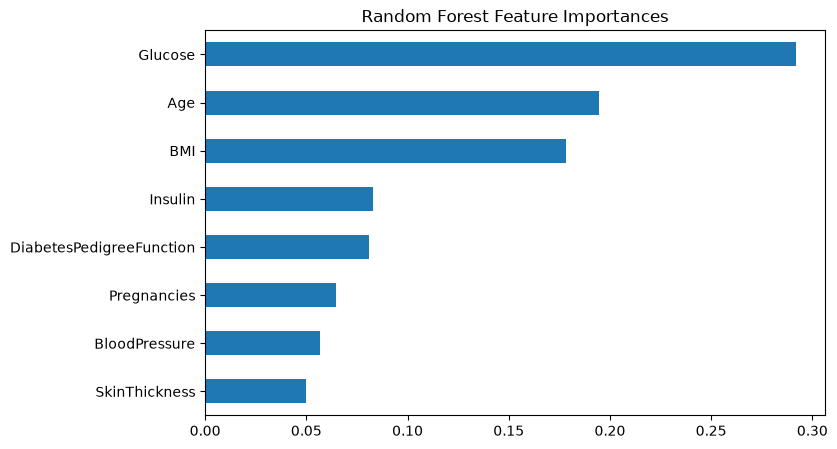

In [12]:
hyperparameters = {
    'n_estimators': np.arange(30, 70),
    'criterion': ['gini', 'entropy'],
    'max_depth': np.arange(3, 8),
    'min_samples_split': np.arange(4, 20),
    'min_samples_leaf': np.arange(3, 10),
    'max_features': ['sqrt'],
    'random_state': [11]
}

tuned_rf_clf = RandomizedSearchCV(rf_clf, hyperparameters, cv=5)
tuned_rf_clf.fit(x_train, y_train)
print("\nBest Random Forest Estimator:\n", tuned_rf_clf.best_estimator_)

rf_model = tuned_rf_clf.best_estimator_
rf_model.fit(x_train, y_train)

# Training Accuracy (Tuned)
y_pred_train = rf_model.predict(x_train)
cnf_matrix = confusion_matrix(y_train, y_pred_train)
print("Random Forest (Tuned) - Confusion Matrix (Train): \n", cnf_matrix)
accuracy = accuracy_score(y_train, y_pred_train)
print("Random Forest (Tuned) - Accuracy (Train): ", accuracy)

# Testing Accuracy (Tuned)
y_pred_test = rf_model.predict(x_test)
cnf_matrix = confusion_matrix(y_test, y_pred_test)
print("Random Forest (Tuned) - Confusion Matrix (Test): \n", cnf_matrix)
accuracy = accuracy_score(y_test, y_pred_test)
print("Random Forest (Tuned) - Accuracy (Test): ", accuracy)

# Feature Importance Visualization[cite: 123, 124]
print("\nRandom Forest Feature Importances:\n", rf_model.feature_importances_)
plt.figure(figsize=(8, 5))
s1 = pd.Series(rf_model.feature_importances_, index=x.columns)
s1 = s1.sort_values()
s1.plot(kind='barh')
plt.title("Random Forest Feature Importances")
plt.show()

# 4. AdaBoost Classifier (Default)

In [13]:
ad_clf = AdaBoostClassifier()
ad_clf.fit(x_train, y_train)

# Training Accuracy
y_pred_train = ad_clf.predict(x_train)
cnf_matrix = confusion_matrix(y_train, y_pred_train)
print("\nAdaBoost (Default) - Confusion Matrix (Train): \n", cnf_matrix)
accuracy = accuracy_score(y_train, y_pred_train)
print("AdaBoost (Default) - Accuracy (Train): ", accuracy)

# Testing Accuracy
y_pred_test = ad_clf.predict(x_test)
cnf_matrix = confusion_matrix(y_test, y_pred_test)
print("AdaBoost (Default) - Confusion Matrix (Test): \n", cnf_matrix)
accuracy = accuracy_score(y_test, y_pred_test)
print("AdaBoost (Default) - Accuracy (Test): ", accuracy)


AdaBoost (Default) - Confusion Matrix (Train): 
 [[352  49]
 [ 72 141]]
AdaBoost (Default) - Accuracy (Train):  0.8029315960912052
AdaBoost (Default) - Confusion Matrix (Test): 
 [[80 19]
 [15 40]]
AdaBoost (Default) - Accuracy (Test):  0.7792207792207793


# 5. AdaBoost Classifier (Hyperparameter Tuning)


Best AdaBoost Estimator:
 AdaBoostClassifier(learning_rate=np.float64(1.3000000000000003),
                   n_estimators=np.int64(54), random_state=11)
AdaBoost (Tuned) - Confusion Matrix (Train): 
 [[358  43]
 [ 74 139]]
AdaBoost (Tuned) - Accuracy (Train):  0.8094462540716613
AdaBoost (Tuned) - Confusion Matrix (Test): 
 [[79 20]
 [17 38]]
AdaBoost (Tuned) - Accuracy (Test):  0.7597402597402597

AdaBoost Feature Importances:
 [0.         0.3069802  0.05249207 0.01520254 0.0293623  0.19810613
 0.21700128 0.18085549]


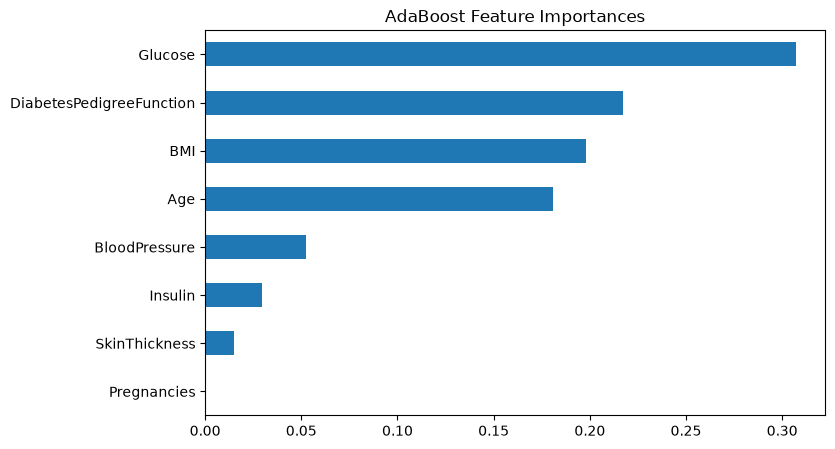

In [14]:
hyperparameters = {
    'n_estimators': np.arange(30, 70),
    'learning_rate': np.arange(0.1, 2.1, 0.1),
    'random_state': [11]
}

tuned_ad_clf = RandomizedSearchCV(ad_clf, hyperparameters, cv=5)
tuned_ad_clf.fit(x_train, y_train)
print("\nBest AdaBoost Estimator:\n", tuned_ad_clf.best_estimator_)

ad_model = tuned_ad_clf.best_estimator_
ad_model.fit(x_train, y_train)

# Training Accuracy (Tuned)
y_pred_train = ad_model.predict(x_train)
cnf_matrix = confusion_matrix(y_train, y_pred_train)
print("AdaBoost (Tuned) - Confusion Matrix (Train): \n", cnf_matrix)
accuracy = accuracy_score(y_train, y_pred_train)
print("AdaBoost (Tuned) - Accuracy (Train): ", accuracy)

# Testing Accuracy (Tuned)
y_pred_test = ad_model.predict(x_test)
cnf_matrix = confusion_matrix(y_test, y_pred_test)
print("AdaBoost (Tuned) - Confusion Matrix (Test): \n", cnf_matrix)
accuracy = accuracy_score(y_test, y_pred_test)
print("AdaBoost (Tuned) - Accuracy (Test): ", accuracy)

# Feature Importance Visualization[cite: 126, 127]
print("\nAdaBoost Feature Importances:\n", ad_model.feature_importances_)
plt.figure(figsize=(8, 5))
s2 = pd.Series(ad_model.feature_importances_, index=x.columns)
s2 = s2.sort_values()
s2.plot(kind='barh')
plt.title("AdaBoost Feature Importances")
plt.show()